# Challenging cases

Symmetry numbers for the four molecules in the "challenging cases" figure of the manuscript.

In [1]:
from IPython.display import display
from rdkit import Chem
from stereomolgraph import StereoMolGraph
from stereomolgraph.algorithms.symmetry import symmetry_number


def report(smiles: str, expected: int) -> None:
    rdmol = Chem.MolFromSmiles(smiles, sanitize=False)
    rdmol.UpdatePropertyCache(strict=True)
    rdmol = Chem.AddHs(rdmol)
    Chem.SanitizeMol(rdmol)

    graph = StereoMolGraph.from_rdmol(
        rdmol, stereo_complete=True, resonance=True, lone_pair_stereo=True
    )
    display(rdmol)

    sym_num = symmetry_number(graph)
    print(f"{sym_num = }")
    assert sym_num == expected, f"expected {expected}"

## (a) TAME (tris(aminomethyl)ethane)

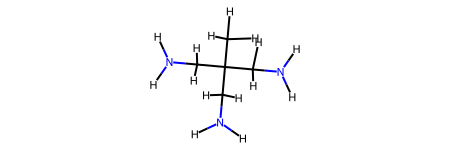

sym_num = 72


In [2]:
report("CC(CN)(CN)CN", expected=72)

## (b) THAM (tris(hydroxymethyl)aminomethane)

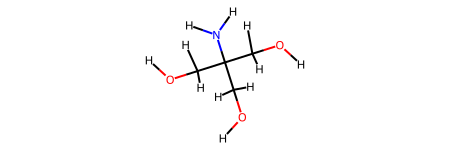

sym_num = 6


In [3]:
report("NC(CO)(CO)CO", expected=6)

## (c) 4-methylbicyclo[2.2.2]octan-1-amine

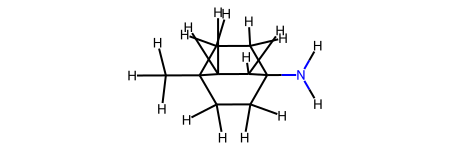

sym_num = 18


In [4]:
report("CC12CCC(N)(CC1)CC2", expected=18)

## (d) p-cresol

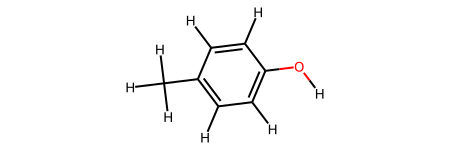

sym_num = 6


In [5]:
report("Cc1ccc(O)cc1", expected=6)